# 01 - Generate the single-transistor datasets (Part A, step 1)

Self-contained notebook: everything it needs is defined below. The only external inputs are the model file, ngspice, and the usual
Python libraries (numpy, pandas, matplotlib).

For each of the four cases (NMOS ON, NMOS OFF, PMOS ON, PMOS OFF) it draws 10,000 random samples (section 4 of the spec),
simulates each one in a one-FET ngspice netlist and stores one CSV per case.
Columns: `vdd, temp, w, vd, vs, vg, vb, vth0, toxe, ndep, u0, xj, id, ig, is, ib`. Currents are terminal currents flowing **into** the device.

## 1. Configuration
Assignment: model file `16nm_HP`, nominal VDD 0.9 V. Everything else follows the sweep ranges of the spec.

In [1]:
import re
import shutil
import subprocess
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# paths: the notebook lives in notebooks/; outputs go to the folders next to it
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODEL_FILE = ROOT / "Model Files-20261105" / "models" / "16nm_HP.pm"     # assigned model file
BUILD_DIR = ROOT / "build"          # scratch space for generated netlists (git-ignored)
NETLIST_DIR = ROOT / "netlists"
DATA_DIR = ROOT / "data"

# assignment and sweep ranges (project spec, section 4)
VDD_NOM = 0.9
LMIN = 16e-9                        # channel length = feature size of the node
WMIN = LMIN
W_RANGE = (1 * LMIN, 8 * LMIN)      # transistor width, uniform
LDIFF = 2 * LMIN                    # diffusion length for the junction areas AD = AS = W * LDIFF
VDD_VAR = 0.10                      # VDD uniform in nominal +/- 10 %
TEMP_RANGE = (-40.0, 125.0)         # degC, uniform
PROC_VAR = 0.10                     # process parameters uniform in nominal +/- 10 %
PROC_PARAMS = ("vth0", "toxe", "ndep", "u0", "xj")

N_SAMPLES = 10_000
SEED = 20261105
# gate and body voltage per case, as a fraction of the sampled VDD
CASES = {
    "nmos_on":  dict(device="nmos", vg=1.0, vb=0.0),
    "nmos_off": dict(device="nmos", vg=0.0, vb=0.0),
    "pmos_on":  dict(device="pmos", vg=0.0, vb=1.0),
    "pmos_off": dict(device="pmos", vg=1.0, vb=1.0),
}
CASE_SEEDS = {name: SEED + i for i, name in enumerate(CASES)}

SPICE_OPTIONS = ".options gmin=1e-18 abstol=1e-18 reltol=1e-6 vntol=1e-9"   # required in every netlist
NUMDGT = 15                         # printed digits; the default 6 breaks the Kirchhoff check
N_WORKERS = 8                       # parallel ngspice processes
CHUNK = 250                         # samples per ngspice process
CURRENTS = ["id", "ig", "is", "ib"]
print(f"model {MODEL_FILE.name} | exists: {MODEL_FILE.exists()} | nominal VDD {VDD_NOM} V | L = Wmin = {LMIN*1e9:.0f} nm")

model 16nm_HP.pm | exists: True | nominal VDD 0.9 V | L = Wmin = 16 nm


## 2. Nominal process parameters from the model file
Read straight from the `.model` cards; every sample is `nominal x U(0.9, 1.1)`, separately for the NMOS and PMOS cards.

In [2]:
def read_cards(path):
    """Return {card_name: text}; continuation lines ('+') are joined to their .model line."""
    cards, cur = {}, None
    for raw in Path(path).read_text().splitlines():
        s = raw.strip()
        if not s or s.startswith("*"):
            continue
        if s.lower().startswith(".model"):
            cur = s.split()[1].lower()
            cards[cur] = [s]
        elif s.startswith("+") and cur:
            cards[cur].append(s[1:])
        else:
            cur = None
    return {k: " ".join(v) for k, v in cards.items()}


_NUM = r"[-+]?[0-9]*\.?[0-9]+(?:[eE][-+]?[0-9]+)?"


def nominal_values(path, params):
    """Return {card_name: {param: value}} for the requested parameters."""
    out = {}
    for name, text in read_cards(path).items():
        vals = {}
        for p in params:
            # (?<![\w.]) keeps e.g. 'vth0' from matching inside 'lvth0' or 'wvth0'
            m = re.search(rf"(?<![\w.]){p}\s*=\s*({_NUM})", text, re.I)
            if m is None:
                raise ValueError(f"parameter {p} not found in card {name}")
            vals[p] = float(m.group(1))
        out[name] = vals
    return out


def nominals():
    return nominal_values(MODEL_FILE, PROC_PARAMS)


pd.DataFrame(nominals()).T

,vth0,toxe,ndep,u0,xj
nmos,0.47965,9.500000e-10,7.000000e+18,0.030,5.000000e-09
pmos,-0.43121,1.000000e-09,5.500000e+18,0.006,5.000000e-09


## 3. ngspice wrapper
Runs ngspice natively if it is on the PATH, otherwise through WSL (Windows). Only stdout is parsed: ngspice writes progress messages to stderr,
and when both streams are merged they can cut result lines in half.

In [3]:
def to_wsl(path):
    """Convert a Windows path to its /mnt/<drive>/... form."""
    p = Path(path).resolve()
    return "/mnt/" + p.drive.rstrip(":").lower() + "/" + "/".join(p.parts[1:])


def prepare_build():
    """Create the scratch directory and copy the model file there (no spaces in the path)."""
    BUILD_DIR.mkdir(exist_ok=True)
    dst = BUILD_DIR / MODEL_FILE.name
    if not dst.exists() or dst.read_bytes() != MODEL_FILE.read_bytes():
        shutil.copyfile(MODEL_FILE, dst)
    return BUILD_DIR


def run_ngspice(cir_name, cwd, merge_stderr=False):
    """Run `ngspice -b cir_name` inside cwd and return its output as text."""
    cwd = Path(cwd)
    if shutil.which("ngspice"):
        r = subprocess.run(["ngspice", "-b", str(cir_name)], cwd=cwd, capture_output=True, text=True, errors="replace")
        return (r.stdout + (r.stderr if merge_stderr else "")).replace("\x00", "")
    cmd = f"cd '{to_wsl(cwd)}' && ngspice -b '{cir_name}'" + (" 2>&1" if merge_stderr else " 2>/dev/null")
    r = subprocess.run(["wsl", "-e", "bash", "-c", cmd], capture_output=True, text=True, errors="replace")
    return r.stdout.replace("\x00", "")


def ngspice_version():
    if shutil.which("ngspice"):
        r = subprocess.run(["ngspice", "--version"], capture_output=True, text=True, errors="replace")
        text = r.stdout + r.stderr
    else:
        r = subprocess.run(["wsl", "-e", "bash", "-c", "ngspice --version 2>&1"], capture_output=True, text=True, errors="replace")
        text = r.stdout.replace("\x00", "")
    m = re.search(r"ngspice-\d+(?:\.\d+)?", text)
    return m.group(0) if m else "unknown"


print("simulator:", ngspice_version())

simulator: ngspice-42


## 4. Netlists
* `example_netlist`: one readable netlist per case (nominal process, one voltage source per terminal, `AD = AS = W x Ldiff`) written to `netlists/`.
* `batch_netlist`: an explicit script that simulates many samples in one ngspice run. Per sample it sets the five process parameters
  (**one `altermod` per parameter**: only the first parameter on an `altermod` line is applied), the temperature, the four bias voltages,
  `W`, `AD` and `AS`, runs `op` and prints the terminal currents plus the node voltages. The node voltages let the parser detect a sample whose operating point failed.

In [4]:
def fmt(x):
    """Number formatting shared by the netlists and the CSV files (10 significant digits)."""
    return f"{float(x):.10g}"


def example_netlist(case, w=None, temp=27.0):
    spec = CASES[case]
    dev = spec["device"]
    w = WMIN if w is None else w
    vdd = VDD_NOM
    vd, vs = (vdd, 0.0) if dev == "nmos" else (0.0, vdd)
    vg, vb = spec["vg"] * vdd, spec["vb"] * vdd
    nom = nominals()[dev]
    inc = f"../{MODEL_FILE.parent.parent.name}/{MODEL_FILE.parent.name}/{MODEL_FILE.name}"
    name = "Mn" if dev == "nmos" else "Mp"
    lines = [
        f"* Single-transistor netlist: {case.replace('_', ' ').upper()} ({MODEL_FILE.stem}, nominal process)",
        f'.include "{inc}"',
        SPICE_OPTIONS,
        "",
        "* geometry and bias of this example (the datasets sample these and the process parameters at random)",
        f".param Lmin={fmt(LMIN)}",
        f".param Ldiff={fmt(LDIFF)}",
        f".param Wd={fmt(w)}",
        f".param vdd={fmt(vdd)}",
        "",
        "* device with junction areas AD = AS = W*Ldiff, one voltage source per terminal",
        f"{name} d g s b {dev} W={{Wd}} L={{Lmin}} AD={{Wd*Ldiff}} AS={{Wd*Ldiff}}",
        f"Vd d 0 {fmt(vd)}",
        f"Vg g 0 {fmt(vg)}",
        f"Vs s 0 {fmt(vs)}",
        f"Vb b 0 {fmt(vb)}",
        "",
        ".control",
        f"set numdgt = {NUMDGT}",
        f"set temp = {fmt(temp)}",
        "* one altermod per parameter (only the first parameter on a line is applied)",
    ]
    lines += [f"altermod {dev} {p}={fmt(nom[p])}" for p in PROC_PARAMS]
    lines += ["op", "print i(vd) i(vg) i(vs) i(vb)", ".endc", ".end", ""]
    return "\n".join(lines)


def batch_netlist(case, df):
    """Explicit script that simulates every row of df; each sample is announced with an `@@ k` marker."""
    dev = CASES[case]["device"]
    r0 = df.iloc[0]
    lines = [
        f"* single-FET batch: {case}",
        f".include {MODEL_FILE.name}",
        SPICE_OPTIONS,
        f"M1 d g s b {dev} W={fmt(r0.w)} L={fmt(LMIN)} AD={fmt(r0.w * LDIFF)} AS={fmt(r0.w * LDIFF)}",
        f"Vd d 0 {fmt(r0.vd)}",
        f"Vg g 0 {fmt(r0.vg)}",
        f"Vs s 0 {fmt(r0.vs)}",
        f"Vb b 0 {fmt(r0.vb)}",
        ".control",
        f"set numdgt = {NUMDGT}",
    ]
    for k, row in enumerate(df.itertuples(index=False)):
        lines.append(f"echo @@ {k}")
        lines += [f"altermod {dev} {p}={fmt(getattr(row, p))}" for p in PROC_PARAMS]
        lines += [
            f"set temp = {fmt(row.temp)}",
            f"alter vd = {fmt(row.vd)}",
            f"alter vg = {fmt(row.vg)}",
            f"alter vs = {fmt(row.vs)}",
            f"alter vb = {fmt(row.vb)}",
            f"alter @m1[w] = {fmt(row.w)}",
            f"alter @m1[ad] = {fmt(row.w * LDIFF)}",
            f"alter @m1[as] = {fmt(row.w * LDIFF)}",
            "op",
            "print i(vd) i(vg) i(vs) i(vb) v(d) v(g) v(s) v(b)",
        ]
    lines += [".endc", ".end", ""]
    return "\n".join(lines)


print(example_netlist("nmos_on"))

* Single-transistor netlist: NMOS ON (16nm_HP, nominal process)
.include "../Model Files-20261105/models/16nm_HP.pm"
.options gmin=1e-18 abstol=1e-18 reltol=1e-6 vntol=1e-9

* geometry and bias of this example (the datasets sample these and the process parameters at random)
.param Lmin=1.6e-08
.param Ldiff=3.2e-08
.param Wd=1.6e-08
.param vdd=0.9

* device with junction areas AD = AS = W*Ldiff, one voltage source per terminal
Mn d g s b nmos W={Wd} L={Lmin} AD={Wd*Ldiff} AS={Wd*Ldiff}
Vd d 0 0.9
Vg g 0 0.9
Vs s 0 0
Vb b 0 0

.control
set numdgt = 15
set temp = 27
* one altermod per parameter (only the first parameter on a line is applied)
altermod nmos vth0=0.47965
altermod nmos toxe=9.5e-10
altermod nmos ndep=7e+18
altermod nmos u0=0.03
altermod nmos xj=5e-09
op
print i(vd) i(vg) i(vs) i(vb)
.endc
.end



## 5. Sampler
Independent random draws per case. VDD is drawn first because Vd and Vs depend on it; Vd and Vs are uniform in [0, VDD];
the gate and body voltages are fixed by the case. Values are rounded to the 10 digits used in the netlists, so the CSV equals what was simulated.

In [5]:
COLUMNS = ["vdd", "temp", "w", "vd", "vs", "vg", "vb", *PROC_PARAMS]


def _round(a):
    return np.array([float(f"{x:.10g}") for x in a])


def draw(case, n, rng):
    spec = CASES[case]
    nom = nominals()[spec["device"]]
    vdd = _round(rng.uniform(VDD_NOM * (1 - VDD_VAR), VDD_NOM * (1 + VDD_VAR), n))
    vd = _round(rng.uniform(0.0, 1.0, n) * vdd)
    vs = _round(rng.uniform(0.0, 1.0, n) * vdd)
    w = _round(rng.uniform(*W_RANGE, n))
    temp = _round(rng.uniform(*TEMP_RANGE, n))
    cols = dict(vdd=vdd, temp=temp, w=w, vd=vd, vs=vs, vg=_round(spec["vg"] * vdd), vb=_round(spec["vb"] * vdd))
    for p in PROC_PARAMS:
        cols[p] = _round(nom[p] * rng.uniform(1 - PROC_VAR, 1 + PROC_VAR, n))
    return pd.DataFrame(cols)[COLUMNS]


draw("nmos_on", 5, np.random.default_rng(CASE_SEEDS["nmos_on"]))

,vdd,temp,w,vd,vs,vg,vb,vth0,toxe,ndep,u0,xj
0,0.947210,102.374556,5.369076e-08,0.172749,0.389591,0.947210,0.0,0.432768,8.801810e-10,7.515770e+18,0.028247,5.268979e-09
1,0.982782,101.045318,5.885693e-08,0.052095,0.836689,0.982782,0.0,0.518878,9.928629e-10,6.878196e+18,0.028219,5.474755e-09
2,0.979216,-36.282165,4.455253e-08,0.225320,0.511495,0.979216,0.0,0.442236,9.400940e-10,6.819136e+18,0.031843,5.112827e-09
3,0.907496,40.368048,8.644431e-08,0.668532,0.539466,0.907496,0.0,0.469688,9.344558e-10,7.206781e+18,0.032142,4.578763e-09
4,0.917868,75.813737,1.083371e-07,0.783207,0.333388,0.917868,0.0,0.459402,8.936648e-10,7.646390e+18,0.027544,5.096820e-09


## 6. Batch runner
Samples are simulated in parallel chunks of 250 (one ngspice process each). The parser takes the four currents of each sample and rejects it if the printed node
voltages differ from the sample's biases (a failed operating point would otherwise leave stale values). Failed samples are logged and redrawn from the same RNG stream.

In [6]:
_LINE = re.compile(r"^(@@) (\d+)$|^([iv])\((\w+)\) = (\S+)$")
_BIAS = ["vd", "vg", "vs", "vb"]


def parse(out, df):
    """Terminal currents (into the device) per sample; NaN where the operating point failed."""
    n = len(df)
    res = np.full((n, 4), np.nan)
    seen, k = {}, None
    for line in out.splitlines():
        m = _LINE.match(line.strip())
        if not m:
            continue
        if m.group(1):
            k = int(m.group(2))
            seen[k] = {}
        elif k is not None:
            seen[k][f"{m.group(3)}({m.group(4)})"] = float(m.group(5))
    for k, d in seen.items():
        if k >= n or len(d) != 8:
            continue
        row = df.iloc[k]
        if all(abs(d[f"v({t})"] - row[v]) < 1e-9 for t, v in zip("dgsb", _BIAS)):
            res[k] = [-d[f"i({v})"] for v in _BIAS]       # current into the device = -I(source)
    return res


def run_chunk(case, df, tag):
    name = f"{case}_{tag}.cir"
    (BUILD_DIR / name).write_text(batch_netlist(case, df), newline="\n")
    return parse(run_ngspice(name, BUILD_DIR), df)


def simulate(case, df, workers=N_WORKERS):
    prepare_build()
    starts = list(range(0, len(df), CHUNK))
    with ThreadPoolExecutor(max_workers=workers) as ex:
        parts = list(ex.map(lambda s: run_chunk(case, df.iloc[s:s + CHUNK], s), starts))
    return np.vstack(parts)


def generate(case, n=N_SAMPLES, workers=N_WORKERS):
    """n valid samples of a case with their currents; failed samples are redrawn."""
    rng = np.random.default_rng(CASE_SEEDS[case])
    df = draw(case, n, rng)
    cur = simulate(case, df, workers)
    bad = np.isnan(cur).any(axis=1)
    failed = []
    while bad.any():
        failed.append(df[bad].copy())
        new = draw(case, int(bad.sum()), rng)
        df.loc[bad, :] = new.to_numpy()
        cur[bad] = simulate(case, new, workers)
        bad = np.isnan(cur).any(axis=1)
    out = df.copy()
    out[CURRENTS] = cur
    return out, failed

## 7. Generate the four datasets
Writes the example netlists (and checks that they simulate), then for each case: generate, check Kirchhoff (the four terminal currents must sum to zero),
re-simulate a few rows on their own and compare with the batch result (nothing may carry over between samples), and write the CSV.

In [7]:
def write_examples():
    NETLIST_DIR.mkdir(exist_ok=True)
    for case in CASES:
        path = NETLIST_DIR / f"single_{case}.cir"
        path.write_text(example_netlist(case), newline="\n")
        out = run_ngspice(path.name, NETLIST_DIR)
        if len(re.findall(r"^i\(v[dgsb]\) = ", out, re.M)) != 4:
            raise RuntimeError(f"{path.name}: simulation failed\n{run_ngspice(path.name, NETLIST_DIR, merge_stderr=True)[-600:]}")


def verify(case, df, n_check=5):
    """Re-simulate a few rows alone; returns the worst relative difference to the batch result."""
    rng = np.random.default_rng(0)
    worst = 0.0
    for k in rng.choice(len(df), size=min(n_check, len(df)), replace=False):
        single = run_chunk(case, df.iloc[[k]][COLUMNS], f"check{k}")[0]
        ref = df.iloc[k][CURRENTS].to_numpy(dtype=float)
        worst = max(worst, float(np.max(np.abs(single - ref) / np.maximum(np.abs(ref), 1e-30))))
    return worst


def generate_all(n=N_SAMPLES, out_dir=DATA_DIR, cases=None, check=5):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    write_examples()
    rows = []
    for case in cases or list(CASES):
        t0 = time.time()
        df, failed = generate(case, n)
        total = df[CURRENTS].sum(axis=1).abs()
        biggest = df[CURRENTS].abs().max(axis=1)
        diff = verify(case, df, check)
        df.to_csv(out_dir / f"{case}.csv", index=False, float_format="%.12g")
        if failed:
            pd.concat(failed).to_csv(BUILD_DIR / f"failed_{case}.csv", index=False)
        rows.append(dict(case=case, rows=len(df), seconds=round(time.time() - t0, 1),
                         redrawn_after_failed_op=sum(len(f) for f in failed),
                         kirchhoff_max_abs_sum_A=float(total.max()),
                         kirchhoff_max_rel=float((total / biggest)[biggest > 1e-12].max()),
                         single_vs_batch_max_rel_diff=diff))
    return pd.DataFrame(rows)


summary = generate_all(N_SAMPLES, DATA_DIR)
summary

,case,rows,seconds,redrawn_after_failed_op,kirchhoff_max_abs_sum_A,kirchhoff_max_rel,single_vs_batch_max_rel_diff
0,nmos_on,10000,17.0,0,1.547043e-15,4.080526e-04,0.0
1,nmos_off,10000,26.3,0,1.047215e-21,1.174992e-14,0.0
2,pmos_on,10000,24.4,0,1.662040e-16,6.433740e-05,0.0
3,pmos_off,10000,17.1,0,1.303776e-15,5.536957e-04,0.0


Kirchhoff: the absolute residual shows the solver accuracy; the relative column is only meaningful where the terminal currents are well above the solver floor (1e-12 A).
`single_vs_batch_max_rel_diff` must be zero (or at solver precision): a sample simulated alone gives the same currents as inside the batch.

## 8. Look at the data

In [8]:
data = {case: pd.read_csv(DATA_DIR / f"{case}.csv") for case in CASES}
for case, d in data.items():
    print(case, d.shape)
data["nmos_on"].head()

nmos_on (10000, 16)
nmos_off (10000, 16)
pmos_on (10000, 16)
pmos_off (10000, 16)


,vdd,temp,w,vd,vs,vg,vb,vth0,toxe,ndep,u0,xj,id,ig,is,ib
0,0.947210,55.560394,6.222471e-08,0.936242,0.922248,0.947210,0,0.500640,9.950628e-10,6.326041e+18,0.028596,5.076167e-09,5.318173e-13,8.260059e-14,-5.635286e-13,-5.114340e-14
1,0.982782,74.057065,1.007547e-07,0.883944,0.459974,0.982782,0,0.474195,1.031049e-09,7.407517e+18,0.031381,4.819423e-09,1.850369e-05,3.896661e-12,-1.850369e-05,-5.995740e-13
2,0.979216,-28.323166,1.013494e-07,0.416363,0.370063,0.979216,0,0.436510,8.573753e-10,6.655703e+18,0.028421,4.945438e-09,2.541988e-05,2.677221e-10,-2.542015e-05,-2.942595e-13
3,0.907496,43.962297,1.154205e-07,0.031093,0.902366,0.907496,0,0.490320,1.041223e-09,6.512842e+18,0.027391,5.108425e-09,-2.217580e-04,2.777313e-10,2.217579e-04,-2.287326e-10
4,0.917868,89.719468,9.704313e-08,0.563080,0.617060,0.917868,0,0.443163,1.029625e-09,6.862823e+18,0.029541,4.621932e-09,-1.917715e-07,8.595347e-13,1.917709e-07,-2.645954e-13


### Do the samples cover the ranges of the spec?
Histograms of the sampled inputs for the NMOS-ON dataset (the other cases use the same generator). Vd and Vs are uniform in [0, VDD], so they are plotted relative to the sample's VDD.

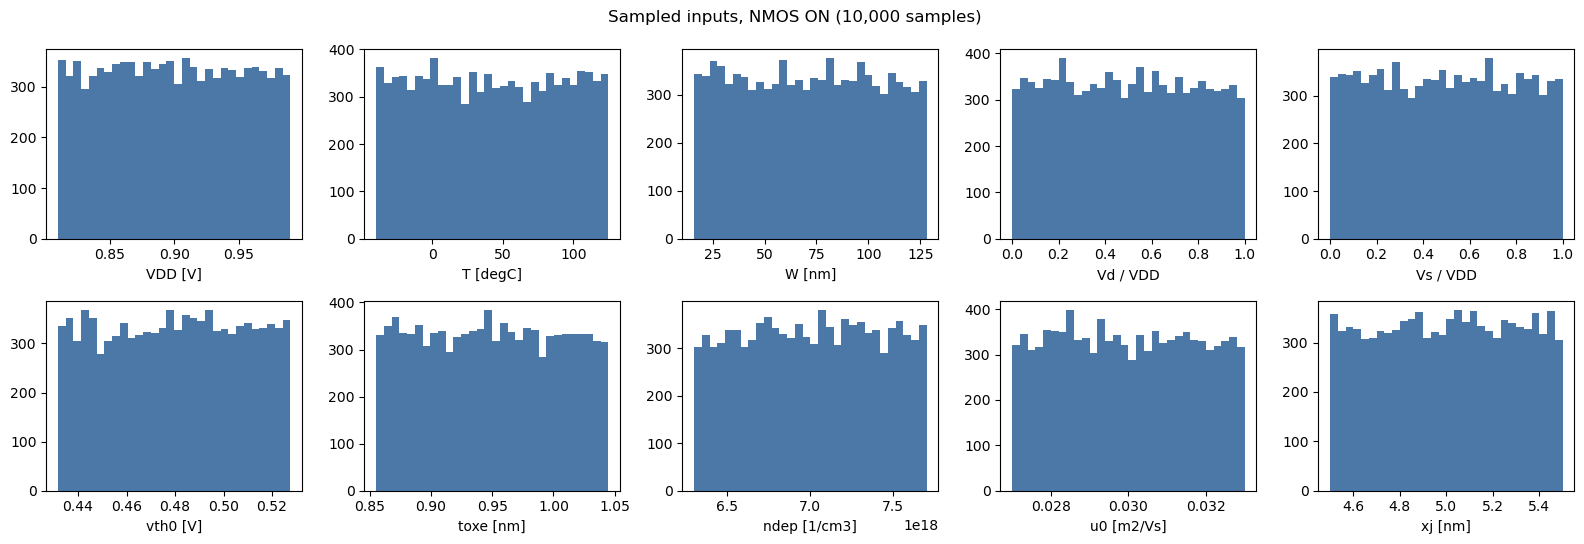

In [9]:
d = data["nmos_on"]
fig, ax = plt.subplots(2, 5, figsize=(16, 5.5))
panels = [(d.vdd, "VDD [V]"), (d.temp, "T [degC]"), (d.w * 1e9, "W [nm]"), (d.vd / d.vdd, "Vd / VDD"), (d.vs / d.vdd, "Vs / VDD"),
          (d.vth0, "vth0 [V]"), (d.toxe * 1e9, "toxe [nm]"), (d.ndep, "ndep [1/cm3]"), (d.u0, "u0 [m2/Vs]"), (d.xj * 1e9, "xj [nm]")]
for a, (x, label) in zip(ax.ravel(), panels):
    a.hist(x, bins=30, color="#4C78A8")
    a.set_xlabel(label)
fig.suptitle("Sampled inputs, NMOS ON (10,000 samples)")
fig.tight_layout()
plt.show()

### How wide are the currents?
Terminal-current magnitudes per case on a log axis. This decides how the targets are treated in the models (log of the magnitude, sign handling);
a terminal with both signs present cannot be modelled with a plain log.

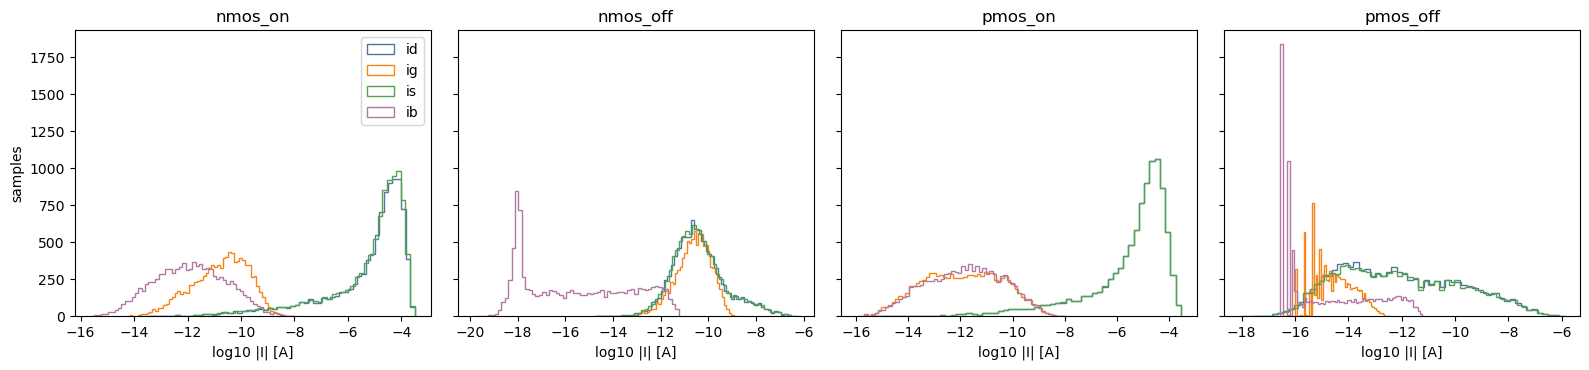

,nmos_on,nmos_off,pmos_on,pmos_off
id,0.49 positive,0.79 positive,0.50 positive,0.32 positive
ig,1.00 positive,0.00 positive,0.00 positive,0.91 positive
is,0.50 positive,0.78 positive,0.50 positive,0.33 positive
ib,0.00 positive,0.00 positive,1.00 positive,0.73 positive


In [10]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for a, (case, d) in zip(ax, data.items()):
    for col, color in zip(CURRENTS, ["#4C78A8", "#F58518", "#54A24B", "#B279A2"]):
        mag = d[col].abs()
        a.hist(np.log10(mag[mag > 0]), bins=60, histtype="step", color=color, label=col)
    a.set_title(case)
    a.set_xlabel("log10 |I| [A]")
ax[0].set_ylabel("samples")
ax[0].legend()
fig.tight_layout()
plt.show()

pd.DataFrame({case: {col: f"{(d[col] > 0).mean():.2f} positive" for col in CURRENTS} for case, d in data.items()})

## 9. Extra samples near the rails (OFF cases)
The 10,000 samples per case above are the datasets of the project (deliverable 1). The gate-level evaluation (notebooks 05 and 07) showed that the OFF models are least accurate exactly where the transistors of a gate operate: at the corners of the (Vd, Vs) square, where a terminal sits at a supply rail or at an internal node close to one. Uniform sampling puts few points there (a point within 3 % of VDD of a given corner of the square has a probability of 0.1 %).

So that the OFF models see this region, **6,000 extra samples** per OFF case are generated with the same procedure and ranges as above, except that each of `Vd` and `Vs` is drawn from a mixture: uniform in [0, VDD] (1/3), within 3 % of VDD of 0 V (1/3), or within 3 % of VDD of VDD (1/3). Everything else (VDD, temperature, width, process parameters, gate and body voltage) is drawn as before. They are used **only as additional training samples** in notebook 03; the validation and test samples are the uniform ones above, apart from 1,000 extra samples that are held out as a separate "rail" validation set. No gate-level SPICE result is used.

In [11]:
N_EXTRA = 6000
EXTRA_MARGIN = 0.03                                  # fraction of VDD
EXTRA_CASES = ["nmos_off", "pmos_off"]
EXTRA_SEEDS = {c: SEED + 100 + i for i, c in enumerate(EXTRA_CASES)}


def draw_rails(case, n, rng, margin=EXTRA_MARGIN):
    spec = CASES[case]
    nom = nominals()[spec["device"]]
    vdd = _round(rng.uniform(VDD_NOM * (1 - VDD_VAR), VDD_NOM * (1 + VDD_VAR), n))

    def volt():
        kind = rng.integers(0, 3, n)                 # 0: uniform, 1: near 0 V, 2: near VDD
        frac = np.where(kind == 0, rng.uniform(0, 1, n), np.where(kind == 1, rng.uniform(0, margin, n), 1 - rng.uniform(0, margin, n)))
        return _round(frac * vdd)

    vd, vs = volt(), volt()
    cols = dict(vdd=vdd, temp=_round(rng.uniform(*TEMP_RANGE, n)), w=_round(rng.uniform(*W_RANGE, n)), vd=vd, vs=vs, vg=_round(spec["vg"] * vdd), vb=_round(spec["vb"] * vdd))
    for p in PROC_PARAMS:
        cols[p] = _round(nom[p] * rng.uniform(1 - PROC_VAR, 1 + PROC_VAR, n))
    return pd.DataFrame(cols)[COLUMNS]


def generate_extra(case, n=N_EXTRA):
    rng = np.random.default_rng(EXTRA_SEEDS[case])
    df = draw_rails(case, n, rng)
    cur = simulate(case, df)
    bad = np.isnan(cur).any(axis=1)
    redrawn = 0
    while bad.any():                                  # failed operating points are redrawn from the same stream
        redrawn += int(bad.sum())
        df.loc[bad, :] = draw_rails(case, int(bad.sum()), rng).to_numpy()
        cur[bad] = simulate(case, df[bad])
        bad = np.isnan(cur).any(axis=1)
    out = df.copy()
    out[CURRENTS] = cur
    return out, redrawn


rows = []
for case in EXTRA_CASES:
    t0 = time.time()
    ex, redrawn = generate_extra(case)
    ex.to_csv(DATA_DIR / f"extra_{case}.csv", index=False, float_format="%.12g")
    total = ex[CURRENTS].sum(axis=1).abs()
    near = lambda s: ((s / ex["vdd"] < EXTRA_MARGIN) | (s / ex["vdd"] > 1 - EXTRA_MARGIN))
    rows.append(dict(case=case, rows=len(ex), seconds=round(time.time() - t0, 1), redrawn_after_failed_op=redrawn, kirchhoff_max_abs_sum_A=float(total.max()),
                     share_vd_within_3pct_of_a_rail=float(near(ex["vd"]).mean()), share_vs_within_3pct_of_a_rail=float(near(ex["vs"]).mean()),
                     share_both_at_rails=float((near(ex["vd"]) & near(ex["vs"])).mean())))
pd.DataFrame(rows)

,case,rows,seconds,redrawn_after_failed_op,kirchhoff_max_abs_sum_A,share_vd_within_3pct_of_a_rail,share_vs_within_3pct_of_a_rail,share_both_at_rails
0,nmos_off,6000,8.4,0,4.568192e-21,0.691667,0.686333,0.473333
1,pmos_off,6000,9.0,0,1.032436e-15,0.697167,0.678000,0.474333


Check: the extra samples satisfy Kirchhoff like the main datasets (the largest residual must be at the solver level), roughly two thirds of the `Vd` and of the `Vs` values lie within 3 % of VDD of a rail (against 6 % for uniform sampling), and the same figure for the uniform datasets above is shown for comparison.

In [12]:
base = {c: pd.read_csv(DATA_DIR / f"{c}.csv") for c in EXTRA_CASES}
share = lambda d: float(((d["vd"] / d["vdd"] < EXTRA_MARGIN) | (d["vd"] / d["vdd"] > 1 - EXTRA_MARGIN)).mean())
print("share of Vd within 3 % of VDD of a rail: main datasets", {c: round(share(d), 3) for c, d in base.items()},
      "| extra samples", {c: round(share(pd.read_csv(DATA_DIR / f'extra_{c}.csv')), 3) for c in EXTRA_CASES})

share of Vd within 3 % of VDD of a rail: main datasets {'nmos_off': 0.057, 'pmos_off': 0.057} | extra samples {'nmos_off': 0.692, 'pmos_off': 0.697}
